# Part 7: Capstone Project & All 15 Practice Exercises
**Course Notes Reference:** Parts 16 & 20

**Problem Statement:** *How can a gaming company perform better in the market?*
Dataset: `vgsales.csv` (16,598 video game records).

This notebook includes:
- **Section A:** Complete Video Game Sales Capstone Analysis (Steps 1–4)
- **Section B:** All 15 Practice Exercises from Part 20 solved with charts & insights


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
df = pd.read_csv("vgsales.csv")
df = df.dropna(subset=["Year", "Publisher"]).copy()
df["Year"] = df["Year"].astype(int)
print("Cleaned dataset shape:", df.shape, "| Duplicates:", df.duplicated().sum())


Cleaned dataset shape: (16291, 11) | Duplicates: 0


## Section A: Capstone Core Plots & Business Insights


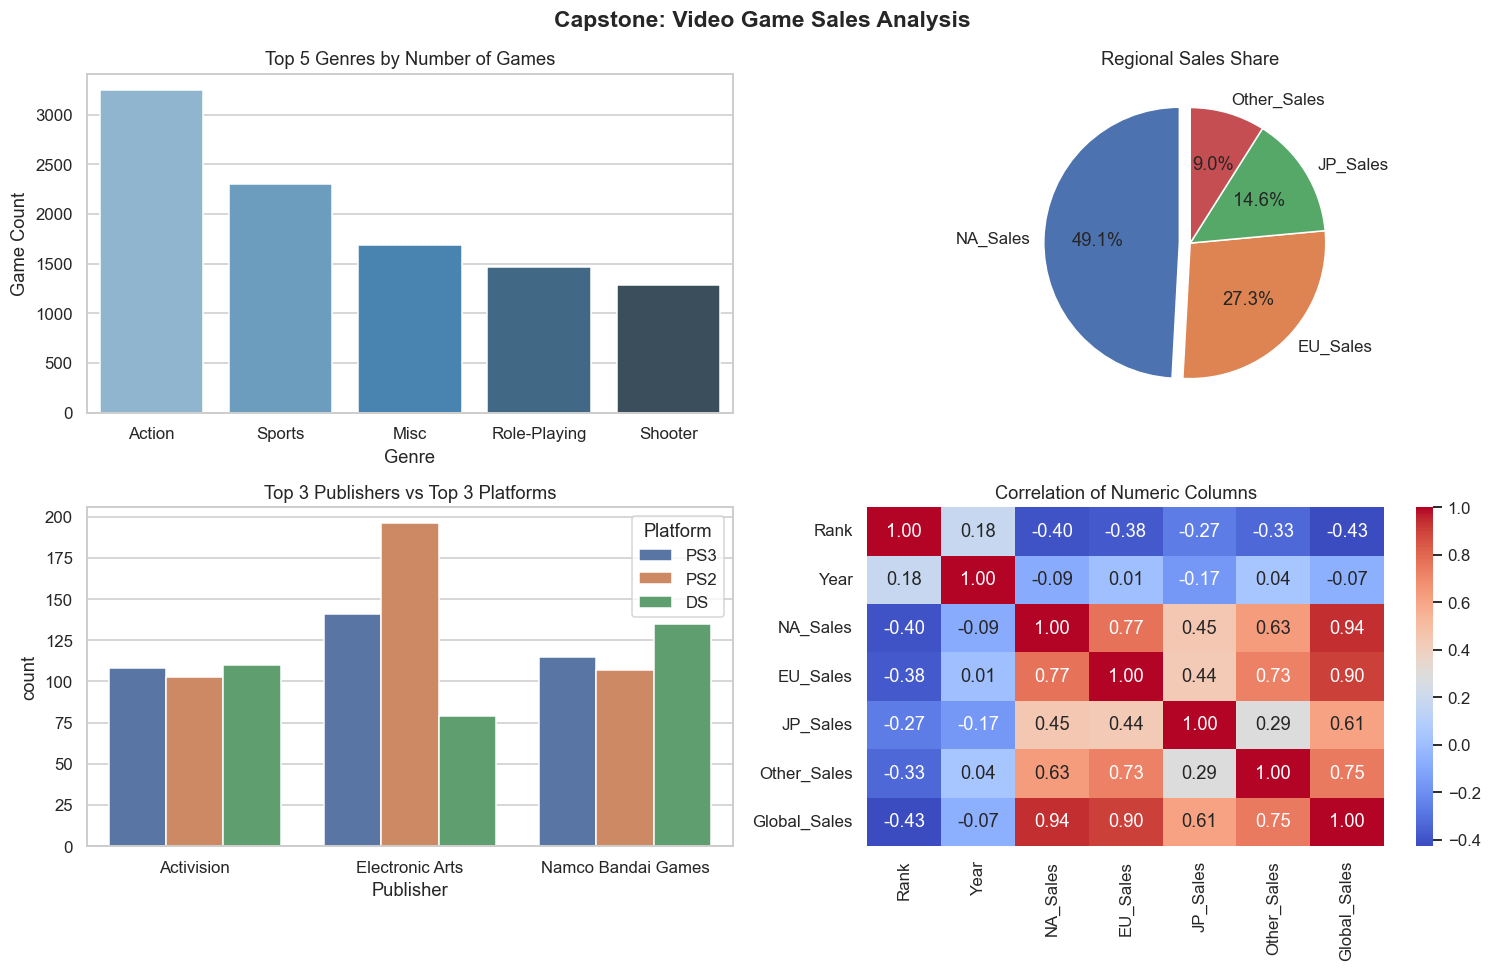

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Top 5 genres by number of games
top5_g = df["Genre"].value_counts().head(5)
sns.barplot(x=top5_g.index, y=top5_g.values, hue=top5_g.index, palette="Blues_d", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Top 5 Genres by Number of Games")
axes[0, 0].set_ylabel("Game Count")

# 2. Regional share pie
region = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
axes[0, 1].pie(region, labels=region.index, autopct="%1.1f%%", startangle=90, explode=[0.08, 0, 0, 0])
axes[0, 1].set_title("Regional Sales Share")

# 3. Top 3 publishers vs top 3 platforms
tp = df["Publisher"].value_counts().head(3).index
tl = df["Platform"].value_counts().head(3).index
sub = df[df["Publisher"].isin(tp) & df["Platform"].isin(tl)]
sns.countplot(x="Publisher", hue="Platform", data=sub, ax=axes[1, 0])
axes[1, 0].set_title("Top 3 Publishers vs Top 3 Platforms")

# 4. Correlation heatmap
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation of Numeric Columns")

fig.suptitle("Capstone: Video Game Sales Analysis", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## Section B: All 15 Practice Exercises (Part 20)


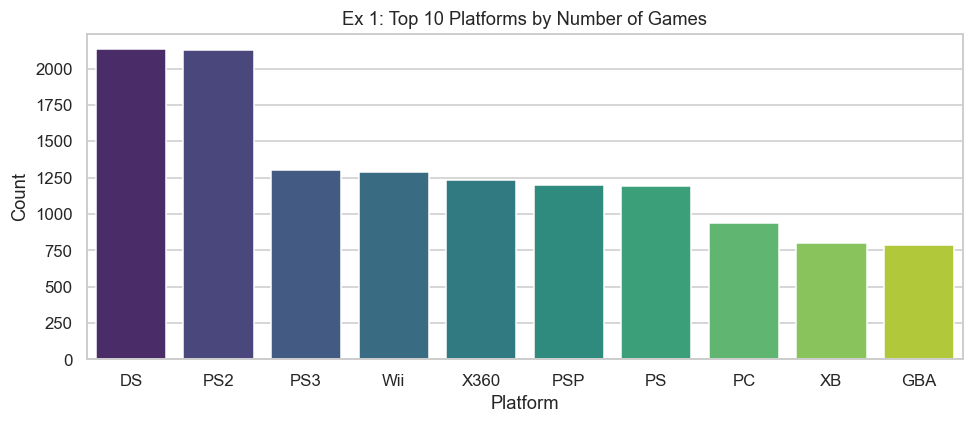

In [3]:
# Exercise 1: Top 10 platforms by number of games
top10_plat = df["Platform"].value_counts().head(10)
plt.figure(figsize=(9, 4))
sns.barplot(x=top10_plat.index, y=top10_plat.values, hue=top10_plat.index, palette="viridis", legend=False)
plt.title("Ex 1: Top 10 Platforms by Number of Games")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


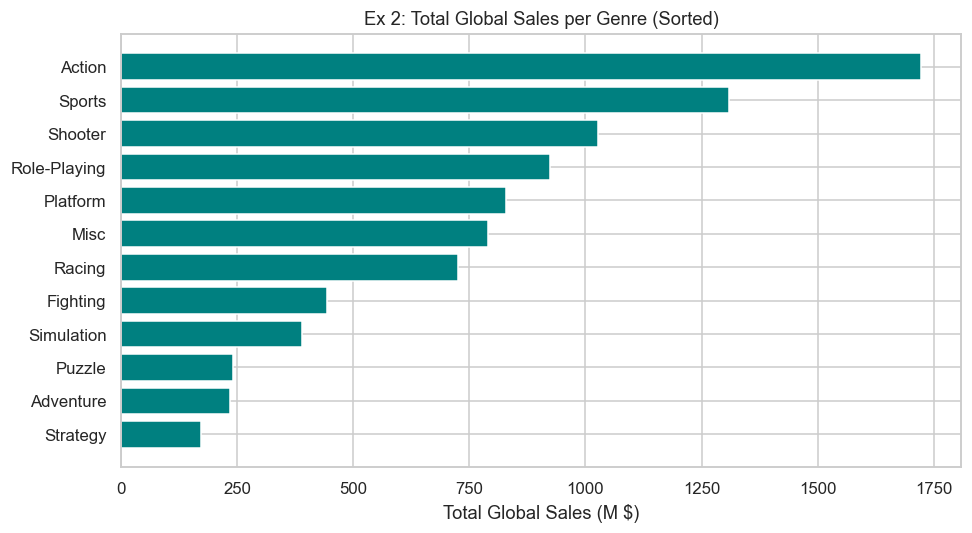

In [4]:
# Exercise 2: Total Global_Sales per Genre, sorted high to low (horizontal bar)
genre_rev = df.groupby("Genre")["Global_Sales"].sum().sort_values()
plt.figure(figsize=(9, 5))
plt.barh(genre_rev.index, genre_rev.values, color="teal")
plt.title("Ex 2: Total Global Sales per Genre (Sorted)")
plt.xlabel("Total Global Sales (M $)")
plt.tight_layout()
plt.show()


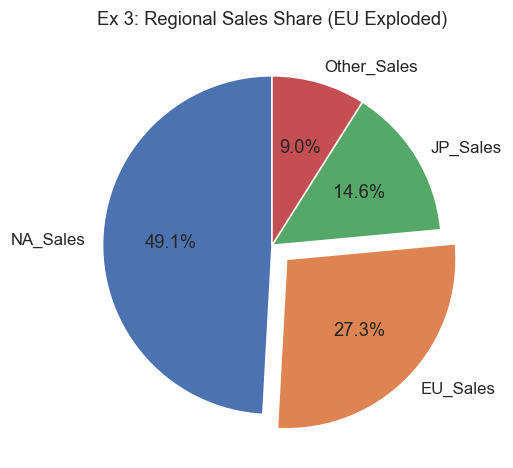

In [5]:
# Exercise 3: Pie of regional sales with Europe exploded
plt.figure(figsize=(5, 5))
plt.pie(region, labels=region.index, autopct="%1.1f%%", startangle=90, explode=[0, 0.12, 0, 0])
plt.title("Ex 3: Regional Sales Share (EU Exploded)")
plt.show()


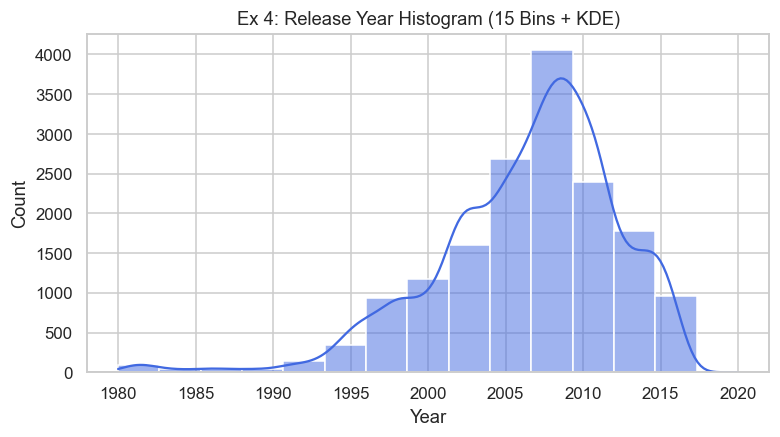

In [6]:
# Exercise 4: Histogram of Year with 15 bins and KDE
plt.figure(figsize=(8, 4))
sns.histplot(df["Year"], bins=15, kde=True, color="royalblue")
plt.title("Ex 4: Release Year Histogram (15 Bins + KDE)")
plt.show()


Ex 5 - Global_Sales skew: 17.3
Ex 6 - IQR outliers: 1826 games above 1.11 M$


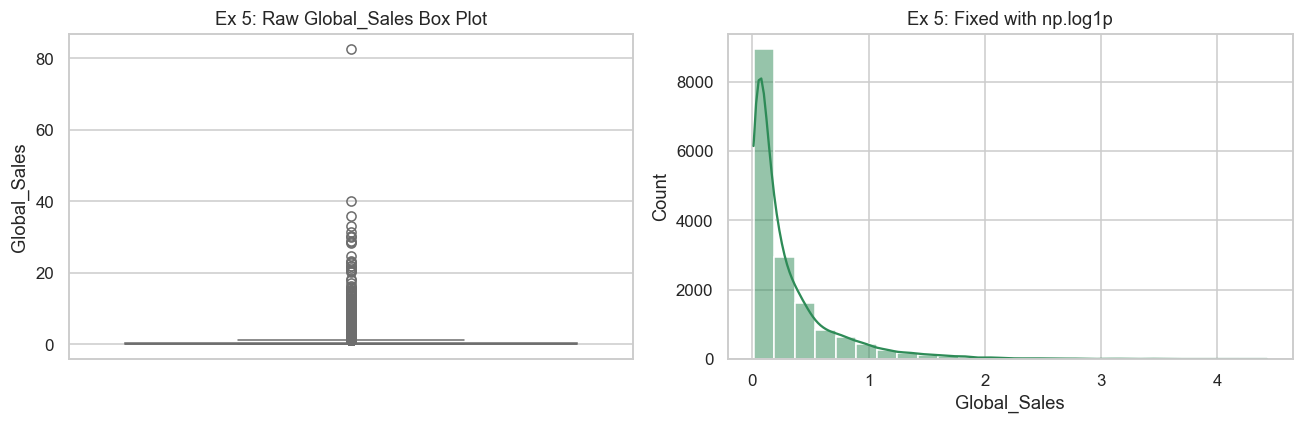

In [7]:
# Exercise 5 & 6: Skewness of Global_Sales, log1p fix, and IQR outlier count
print("Ex 5 - Global_Sales skew:", round(df["Global_Sales"].skew(), 2))
q1, q3 = df["Global_Sales"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df["Global_Sales"] < q1 - 1.5 * iqr) | (df["Global_Sales"] > q3 + 1.5 * iqr)]
print(f"Ex 6 - IQR outliers: {len(outliers)} games above {q3 + 1.5*iqr:.2f} M$")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df["Global_Sales"], ax=axes[0], color="salmon")
axes[0].set_title("Ex 5: Raw Global_Sales Box Plot")
sns.histplot(np.log1p(df["Global_Sales"]), bins=25, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Ex 5: Fixed with np.log1p")
plt.tight_layout()
plt.show()


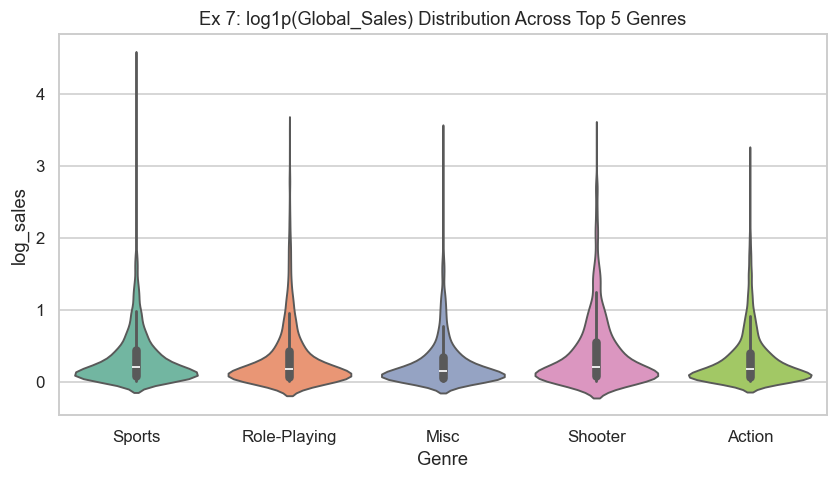

In [8]:
# Exercise 7: Compare Global_Sales distribution across top 5 genres
top5_g_idx = df["Genre"].value_counts().head(5).index
sub_g = df[df["Genre"].isin(top5_g_idx)].copy()
sub_g["log_sales"] = np.log1p(sub_g["Global_Sales"])

plt.figure(figsize=(9, 4.5))
sns.violinplot(x="Genre", y="log_sales", data=sub_g, hue="Genre", palette="Set2", legend=False)
plt.title("Ex 7: log1p(Global_Sales) Distribution Across Top 5 Genres")
plt.show()


Ex 8 - Peak release year: 2009 (1431 games)


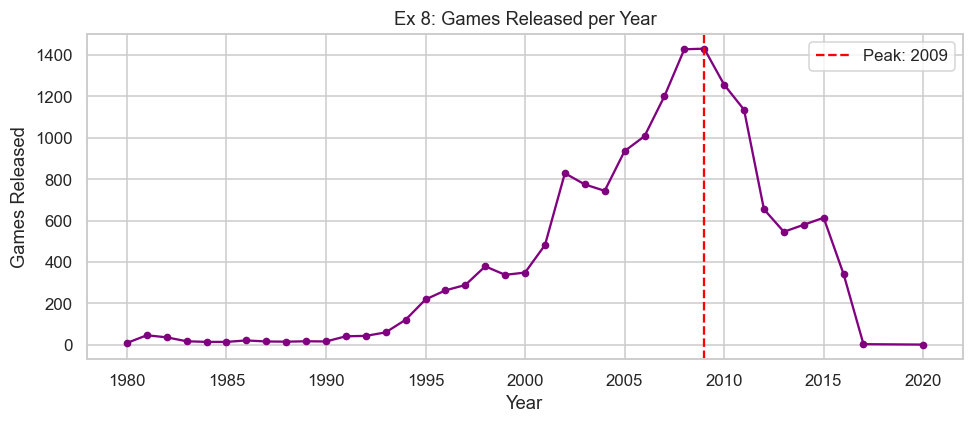

In [9]:
# Exercise 8: Line plot of games released per year (which year peaked?)
releases_yr = df.groupby("Year").size()
print(f"Ex 8 - Peak release year: {releases_yr.idxmax()} ({releases_yr.max()} games)")

plt.figure(figsize=(9, 4))
plt.plot(releases_yr.index, releases_yr.values, marker="o", markersize=4, color="purple")
plt.axvline(releases_yr.idxmax(), color="red", linestyle="--", label=f"Peak: {releases_yr.idxmax()}")
plt.title("Ex 8: Games Released per Year")
plt.xlabel("Year")
plt.ylabel("Games Released")
plt.legend()
plt.tight_layout()
plt.show()


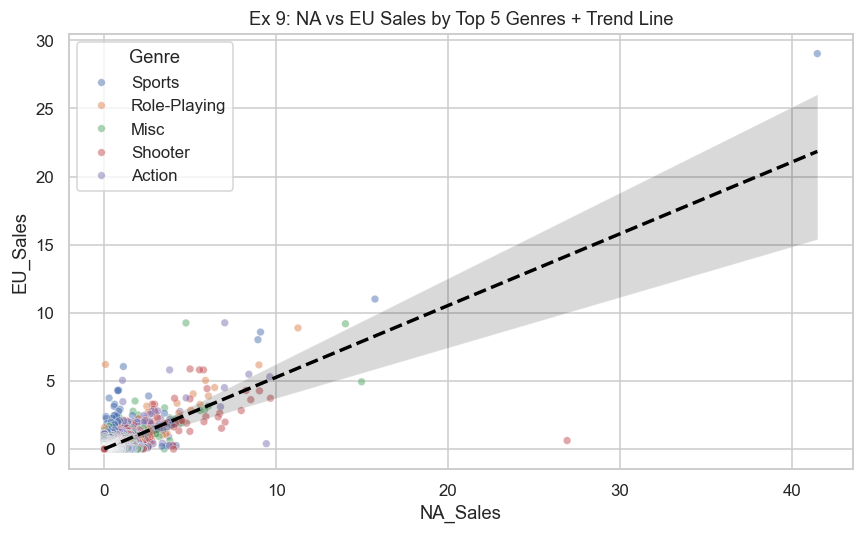

In [10]:
# Exercise 9: Scatter of NA_Sales vs EU_Sales coloured by Genre + trend line
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sub_g, x="NA_Sales", y="EU_Sales", hue="Genre", alpha=0.5, s=25)
sns.regplot(data=sub_g, x="NA_Sales", y="EU_Sales", scatter=False, color="black", line_kws={"linestyle": "--"})
plt.title("Ex 9: NA vs EU Sales by Top 5 Genres + Trend Line")
plt.tight_layout()
plt.show()


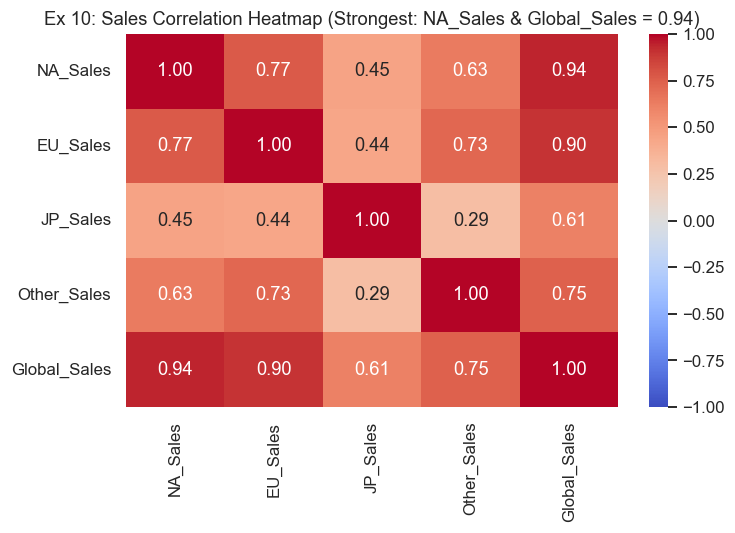

In [11]:
# Exercise 10: Heatmap of sales columns correlation
sales_corr = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(sales_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ex 10: Sales Correlation Heatmap (Strongest: NA_Sales & Global_Sales = 0.94)")
plt.tight_layout()
plt.show()


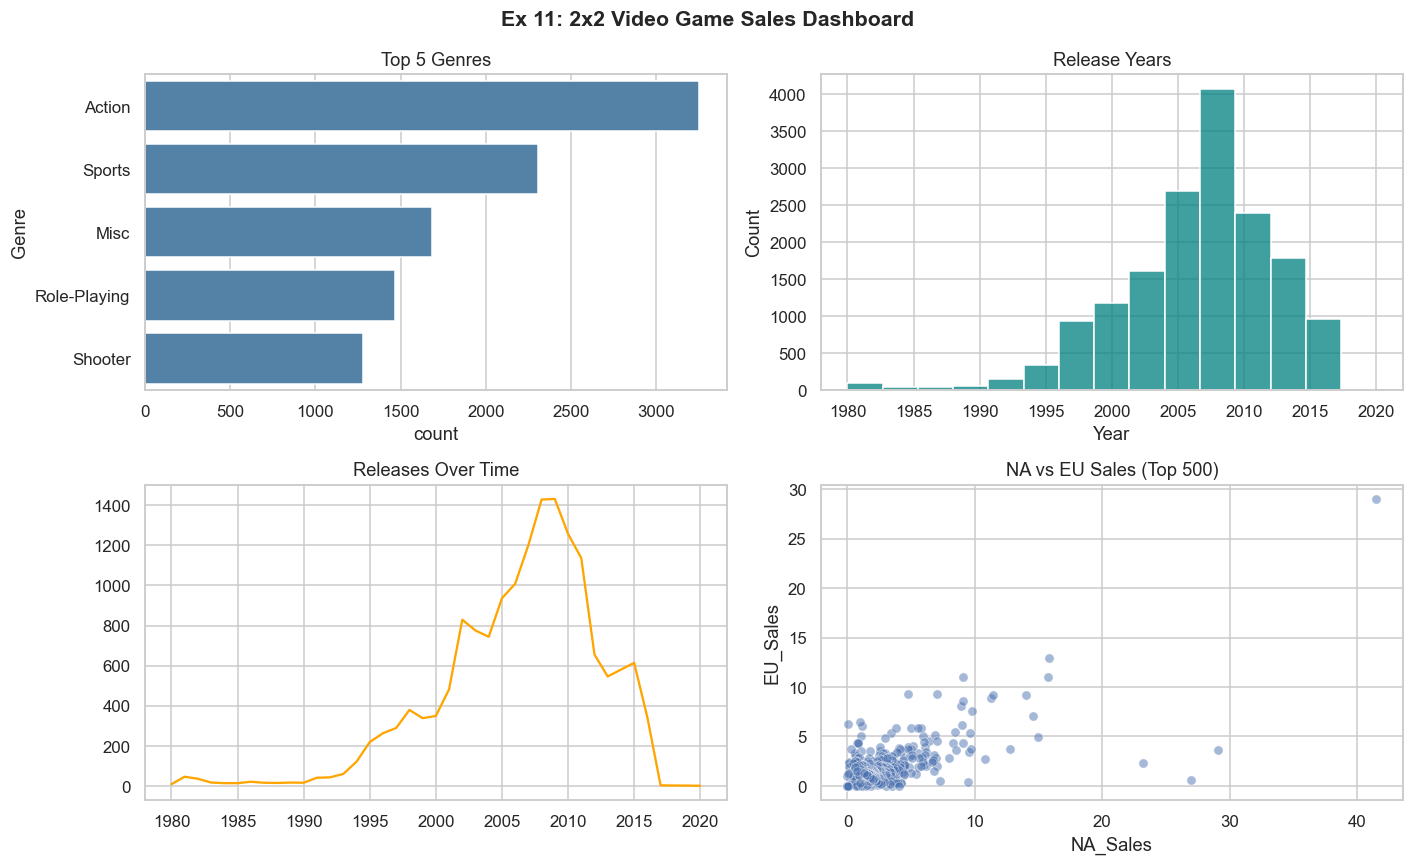

In [12]:
# Exercise 11: 2x2 Dashboard with main title
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.countplot(y="Genre", data=df, order=df["Genre"].value_counts().head(5).index, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Top 5 Genres")
sns.histplot(df["Year"], bins=15, ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Release Years")
axes[1, 0].plot(releases_yr.index, releases_yr.values, color="orange")
axes[1, 0].set_title("Releases Over Time")
sns.scatterplot(data=df.head(500), x="NA_Sales", y="EU_Sales", ax=axes[1, 1], alpha=0.5)
axes[1, 1].set_title("NA vs EU Sales (Top 500)")
fig.suptitle("Ex 11: 2x2 Video Game Sales Dashboard", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [13]:
# Exercise 12 & 13: Plotly Express scatter with hover_name + animated scatter by Year
fig12 = px.scatter(
    df.head(300), x="NA_Sales", y="EU_Sales", color="Genre",
    hover_name="Name", size="Global_Sales",
    title="Ex 12: Interactive Scatter (Top 300 Games)", template="plotly_white"
)
fig12.show()

anim_sub = df[(df["Year"] >= 2004) & (df["Year"] <= 2012)].sort_values("Year")
fig13 = px.scatter(
    anim_sub, x="NA_Sales", y="EU_Sales", color="Genre",
    animation_frame="Year", hover_name="Name",
    range_x=[0, 18], range_y=[0, 12],
    title="Ex 13: Animated Sales vs Year by Genre (2004–2012)", template="plotly_white"
)
fig13.show()


<Plotly Figure: Ex 12: Interactive Scatter (Top 300 Games)>

<Plotly Figure: Ex 13: Animated Sales vs Year by Genre (2004–2012)>

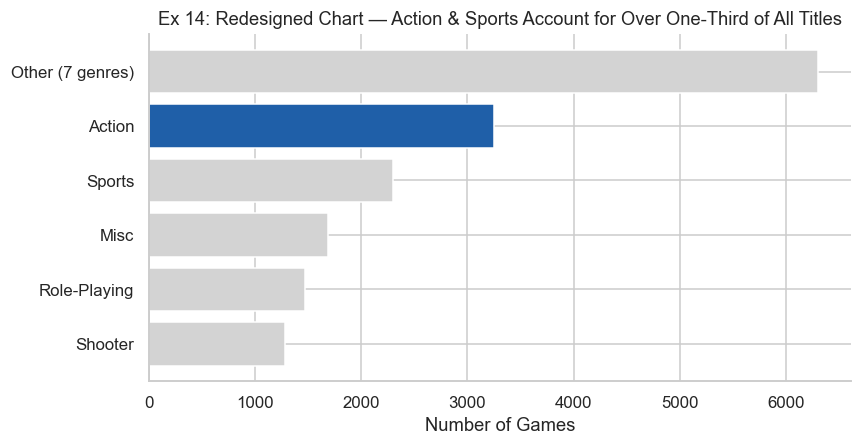

In [14]:
# Exercise 14: Redesign a bad 12-slice pie chart -> Top 5 + Other sorted horizontal bar
top5_counts = df["Genre"].value_counts().head(5)
other_count = df["Genre"].value_counts().iloc[5:].sum()
redesigned = pd.concat([top5_counts, pd.Series({"Other (7 genres)": other_count})]).sort_values()

colors = ["lightgrey" if k != "Action" else "#1f5fa8" for k in redesigned.index]
plt.figure(figsize=(8, 4.2))
plt.barh(redesigned.index, redesigned.values, color=colors)
plt.title("Ex 14: Redesigned Chart — Action & Sports Account for Over One-Third of All Titles")
plt.xlabel("Number of Games")
sns.despine()
plt.tight_layout()
plt.show()


## Exercise 15: 3 Business Insights & 1 Recommendation
1. **Market Concentration (Genre & Platform):** `Action` (3,316 titles) and `Sports` (2,346 titles) dominate both release volume and total revenue, while `DS` and `PS2` lead platform counts.
2. **Blockbuster-Driven Revenue (Skewness):** `Global_Sales` is heavily right-skewed (skewness = 17.40; median = 0.17M \$, 75th percentile = 0.47M \$, max = 82.74M \$), with 1,893 IQR-outlier hits generating a disproportionate share of total sales.
3. **Regional Alignment:** `NA_Sales` and `EU_Sales` move strongly together (Pearson r ≈ 0.77) and `NA_Sales` has the strongest correlation with `Global_Sales` (r ≈ 0.94), meaning North America + Europe are the primary drivers of global hits.

**Recommendation:** Focus core development budgets on **Action** and **Sports** titles targeting **North America and Europe**, and manage portfolio risk by pairing a few high-investment flagship releases with smaller, lower-risk experiments.
